# Pan-cancer pooled ROC (pretrained three-head model)

Counterpart of `CODEX_hcc/Pred_statistic_visual_hcc_all.ipynb` **Pooled StarDist ROC**, but labels are the pan-cancer L1 / L12 / L2 ontology.

Both CV protocols are trained and predicted. Cross-section was retrained 2026-10-13 with P5CRC in the CV (896 slides). Cross-celltype is still the 2026-10-02 run (895 slides, no P5CRC).

| | cross-section | cross-celltype |
|--|--|--|
| train | `result_all_spatial/` | `result_cell_stratified_spatial/` |
| predict | `pred_all_spatial/` | `pred_cell_stratified_spatial/` |
| slides / cells | 896 / 5,627,071 | 895 / 5,510,950 |
| OOF L2 macro AUROC | 0.888 | 0.807 |

1. Early cells: pooled OvR ROC from **section-CV** `pred_all_spatial/stardist_roc/`.
2. Later cells: the same plots from **cell-stratified** `pred_cell_stratified_spatial/`, plus fold OOF and per-class deltas.
3. Hold-out cancers (Prostate) still need UNI matched h5ads.

```bash
conda activate SeededNTM
bash code/PanCancer/demo.sh status
# bash code/PanCancer/demo.sh section predict
# bash code/PanCancer/demo.sh celltype predict
```


In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import pandas as pd

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
PKG = REPO / "code" / "Hist2Pheno_pkg"
PAN = REPO / "code" / "PanCancer"
for p in (PKG, PAN):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from uni_label_cv_helpers import plot_pooled_stardist_tier_rocs

PRED = REPO / "data" / "PanCancer" / "pred_all_spatial"
ROC_ROOT = PRED / "stardist_roc"
OUT = PRED / "pooled_roc"
OUT.mkdir(parents=True, exist_ok=True)
print("ROC_ROOT", ROC_ROOT, "exists", ROC_ROOT.is_dir())
print("n sample dirs", len(list(ROC_ROOT.glob("*"))) if ROC_ROOT.is_dir() else 0)

met = PRED / "metrics_per_section.csv"
if met.is_file():
    df = pd.read_csv(met)
    print(df.groupby("dataset")[["macro_auc_L1_cells", "macro_auc_L12_cells", "macro_auc_L2_cells"]].mean())
    display(df.head())

ROC_ROOT /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_all_spatial/stardist_roc exists True
n sample dirs 896
                macro_auc_L1_cells  macro_auc_L12_cells  macro_auc_L2_cells
dataset                                                                    
BRCA                      0.881023             0.842856            0.812740
CRC                       0.715273             0.723666            0.685956
GBM                       0.601802             0.618054            0.615394
GIST                      0.657196             0.636736            0.633945
HCC                       0.780690             0.763424            0.736299
Lung                      0.679295             0.689398            0.663905
LungIncomplete                 NaN                  NaN                 NaN
PDAC                      0.785030             0.772976            0.727920


,section_id,dataset,sample,n_matched,n_stardist_all,macro_auc_L1,macro_auc_L12,macro_auc_L2,panel,macro_auc_L1_cells,macro_auc_L12_cells,macro_auc_L2_cells
0,Lung::THD0008,Lung,THD0008,34402,113389,0.592774,0.621689,0.627714,/nobackup2/users/lingyu/Python/Hist2Pheno/data...,0.592774,0.621689,0.627714
1,Lung::THD0011,Lung,THD0011,22034,56677,0.582242,0.589581,0.568254,/nobackup2/users/lingyu/Python/Hist2Pheno/data...,0.582242,0.589581,0.568254
2,Lung::TILD117LA,Lung,TILD117LA,9304,75608,0.721852,0.754717,0.705328,/nobackup2/users/lingyu/Python/Hist2Pheno/data...,0.721852,0.754717,0.705328
3,Lung::TILD117MA1,Lung,TILD117MA1,8004,121456,0.785000,0.775589,0.723897,/nobackup2/users/lingyu/Python/Hist2Pheno/data...,0.785000,0.775589,0.723897
4,Lung::TILD175MA,Lung,TILD175MA,14132,72654,0.760221,0.777959,0.702635,/nobackup2/users/lingyu/Python/Hist2Pheno/data...,0.760221,0.777959,0.702635


## Pooled ROC (matched UNI cells, pan-cancer L1 / L12 / L2)

Uses the same CSV layout as cohort StarDist AUROC tables so `plot_pooled_stardist_tier_rocs` can concatenate all sections.



=== L2 | discovering validation_external_stardist_matched_AUROC.csv ===
  BRCA__rep1: 157,016 cells, 20 local classes
  BRCA__rep2: 107,180 cells, 20 local classes
  CRC__P1CRC: 149,492 cells, 20 local classes
  CRC__P2CRC: 202,900 cells, 20 local classes
  CRC__P5CRC: 116,121 cells, 20 local classes
  GBM__P174511_Initial: 35,961 cells, 20 local classes
  GBM__P179161_Recurrent: 135,055 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg002: 3,098 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg004: 12,062 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg005: 4,090 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg006: 5,225 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg007: 10,544 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg008: 6,964 cells, 20 local classe

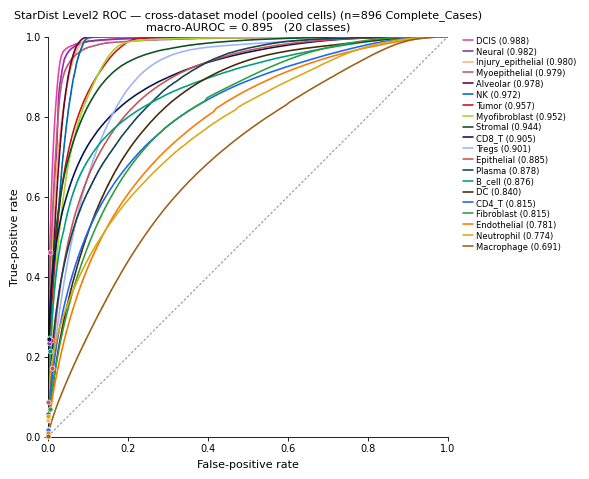

Pooled macro AUROC (L2): 0.8947
  ✓ Saved AUROC bars: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_all_spatial/pooled_roc/roc_stardist_l2_cross_dataset_all_Complete_Cases_per_class_auc.pdf


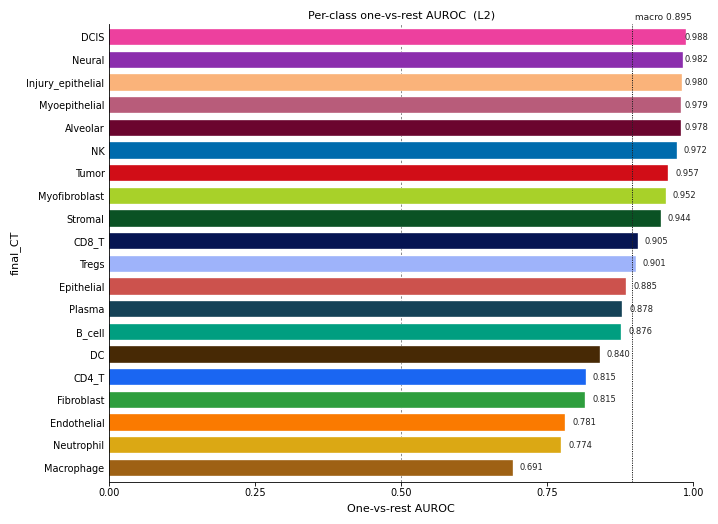


=== L12 | discovering validation_external_stardist_matched_AUROC_level12.csv ===
  BRCA__rep1: 157,016 cells, 8 local classes
  BRCA__rep2: 107,180 cells, 8 local classes
  CRC__P1CRC: 149,492 cells, 8 local classes
  CRC__P2CRC: 202,900 cells, 8 local classes
  CRC__P5CRC: 116,121 cells, 8 local classes
  GBM__P174511_Initial: 35,961 cells, 8 local classes
  GBM__P179161_Recurrent: 135,055 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg002: 3,098 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg004: 12,062 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg005: 4,090 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg006: 5,225 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg007: 10,544 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg008: 6,964 cells, 8 local classes
  GI

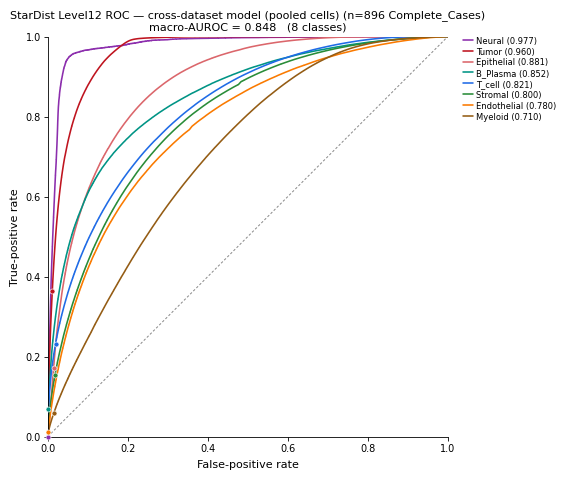

Pooled macro AUROC (L12): 0.8477
  ✓ Saved AUROC bars: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_all_spatial/pooled_roc/roc_stardist_l12_cross_dataset_all_Complete_Cases_per_class_auc.pdf


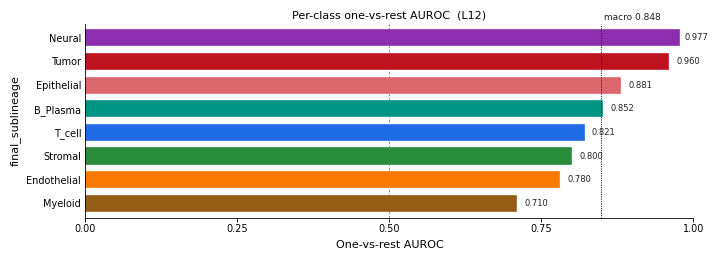


=== L1 | discovering validation_external_stardist_matched_AUROC_level1.csv ===
  BRCA__rep1: 157,016 cells, 5 local classes
  BRCA__rep2: 107,180 cells, 5 local classes
  CRC__P1CRC: 149,492 cells, 5 local classes
  CRC__P2CRC: 202,900 cells, 5 local classes
  CRC__P5CRC: 116,121 cells, 5 local classes
  GBM__P174511_Initial: 35,961 cells, 5 local classes
  GBM__P179161_Recurrent: 135,055 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg002: 3,098 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg004: 12,062 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg005: 4,090 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg006: 5,225 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg007: 10,544 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg008: 6,964 cells, 5 local classes
  GIST

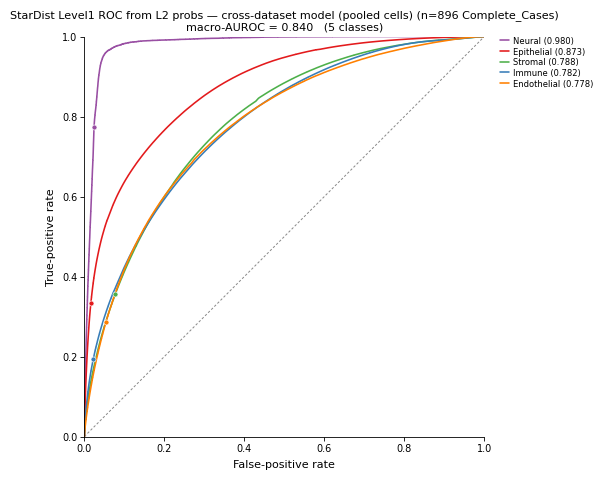

Pooled macro AUROC (L1): 0.8402
  ✓ Saved AUROC bars: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_all_spatial/pooled_roc/roc_stardist_l1_cross_dataset_all_Complete_Cases_per_class_auc.pdf


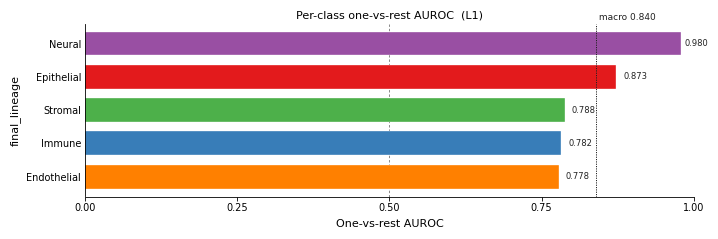

pooled L2 macro AUROC = 0.8947
pooled L12 macro AUROC = 0.8477
pooled L1 macro AUROC = 0.8402


In [2]:
if not ROC_ROOT.is_dir() or not any(ROC_ROOT.iterdir()):
    raise FileNotFoundError(
        f"No per-section AUROC CSVs under {ROC_ROOT}. "
        "Run code/PanCancer/PanCancer_predict_visualize.py first."
    )

results = plot_pooled_stardist_tier_rocs(
    ROC_ROOT,
    OUT,
    tiers=("l2", "l12", "l1"),
    layout="pooled_stardist",
    pan_organ="pancancer",
    figsize=(4.0, 4.0),
    show_barplot=True,
    save_per_class_csv=True,
    show=True,
)
for tier, rec in results.items():
    info = rec.get("roc_info") or {}
    print(f"pooled {tier.upper()} macro AUROC = {info.get('macro_auc', float('nan')):.4f}")

## Hold-out cancers (Prostate and others under `data/`)

Section-CV weights: `data/PanCancer/result_all_spatial/cross_dataset_cv/D_emph_L2_spatial_pancancer/best_mlp_gpu.pt`

Cell-stratified weights: `data/PanCancer/result_cell_stratified_spatial/cross_dataset_cv/D_emph_L2_spatial_pancancer_cellstrat/best_mlp_gpu.pt`

| Folder | Status |
|--------|--------|
| `data/ST/Prostate` | HE + StarDist; **no** `{sample}_matched_features.h5ad` yet |
| `data/Visium/Prostate` | Visium counts; needs HE alignment + UNI + h5ad |

Apply a pan-cancer checkpoint only after a matched UNI h5ad exists, then:

```bash
python -u code/PanCancer/PanCancer_predict_visualize.py \
  --checkpoint data/PanCancer/result_all_spatial/cross_dataset_cv/D_emph_L2_spatial_pancancer/best_mlp_gpu.pt \
  --index-csv /path/to/prostate_section_index.csv
```

Native labels (if any) should map through `celltype_pancancer` aliases, or leave GT empty and only inspect StarDist-all spatial maps.


## Cross-section vs cross-celltype (both complete)

Section-CV and cell-stratified CV use the same three-head spatial model (k=8). They differ only in how cells are split:

- **cross-section:** each HE section is wholly train or val (`GroupKFold` on section IDs).
- **cross-celltype:** `StratifiedKFold` on `L1|L12|L2`; cells from the same section can appear in both splits (spatial neighbors are split-masked). OOF is therefore optimistic vs a new slide.

Train 3b finished all 5 folds + `he_validate`; `demo.sh celltype predict` wrote 896 StarDist AUROC dirs. The cells below compare:

1. Fold OOF AUROC / F1 from `group_cv_folds.csv` (same estimator on both sides).
2. Per-dataset mean AUROC from `metrics_per_section.csv`.
3. Pooled StarDist ROC and per-class OvR AUROC (`pred_*/stardist_roc/`).


,protocol,best_mlp,n_fold_ckpt,pred_roc_dirs
0,cross-section,True,5,896
1,cross-celltype,False,0,896


,protocol,n_cells,n_folds,best_fold,oof_l2_macro_auc,cv_l2_macro_f1_mean
0,cross-section,5627071,5,0,0.888393,0.292099
1,cross-celltype,5510950,5,0,0.806559,0.120046


OOF L2 macro AUROC  section=0.8884  celltype=0.8066


,L1_section,L12_section,L2_section,L1_celltype,L12_celltype,L2_celltype
dataset,,,,,,
BRCA,0.881023,0.842856,0.812740,0.852085,0.823191,0.792747
CRC,0.715273,0.723666,0.685956,0.598774,0.566738,0.525173
GBM,0.601802,0.618054,0.615394,0.515413,0.519340,0.516109
GIST,0.657196,0.636736,0.633945,0.566796,0.555908,0.543141
HCC,0.780690,0.763424,0.736299,0.669749,0.674859,0.638723
Lung,0.679295,0.689398,0.663905,0.634869,0.632710,0.617886
LungIncomplete,NaN,NaN,NaN,NaN,NaN,NaN
PDAC,0.785030,0.772976,0.727920,0.665117,0.653973,0.620544


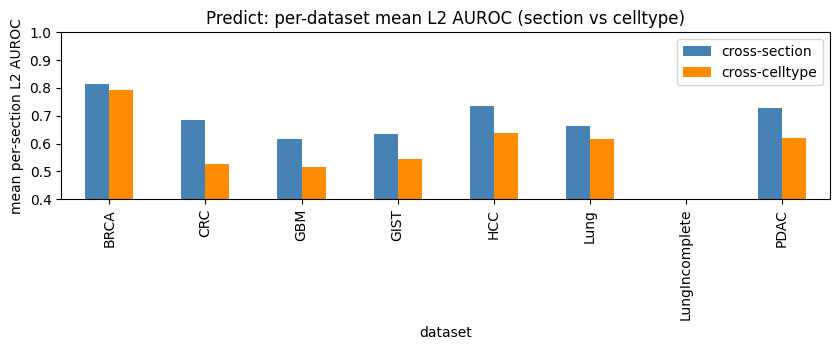

section OOF L2 ROC /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/result_all_spatial/roc_internal_level2_oof.png


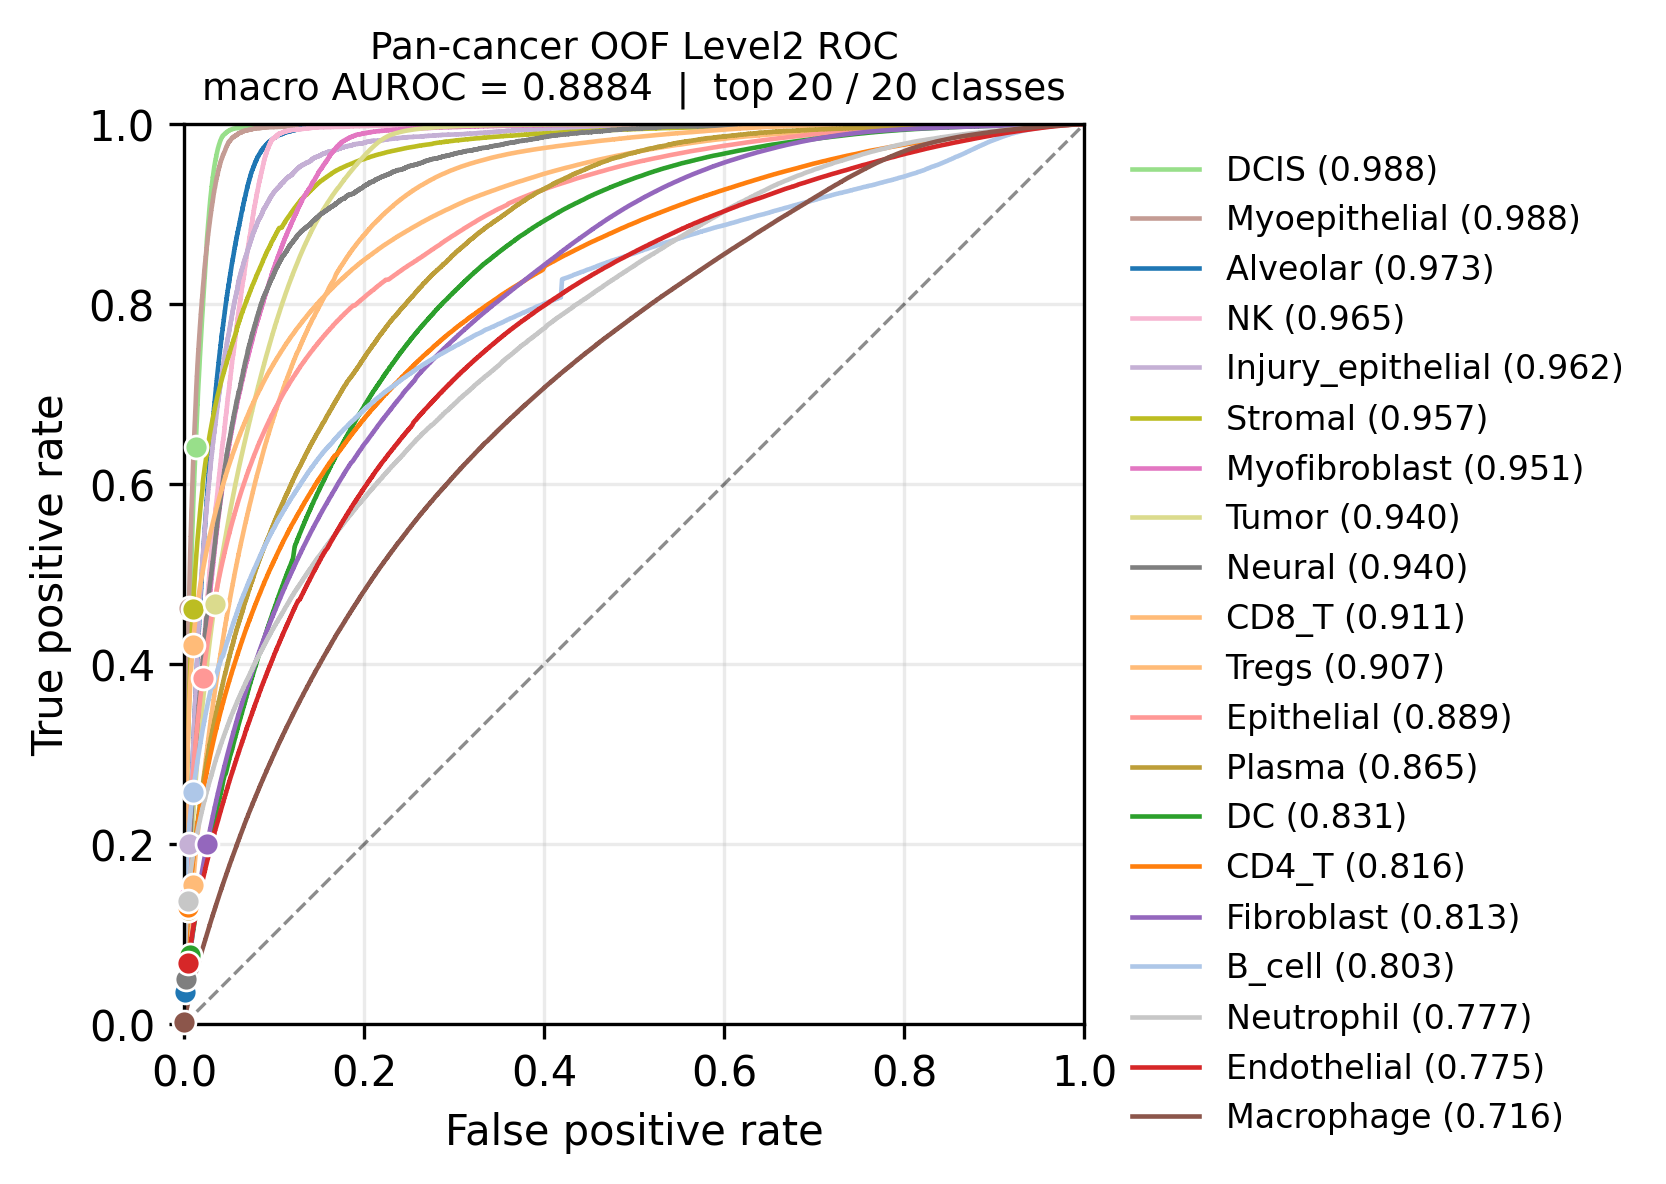

celltype OOF L2 ROC /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/result_cell_stratified_spatial/roc_internal_level2_oof.png


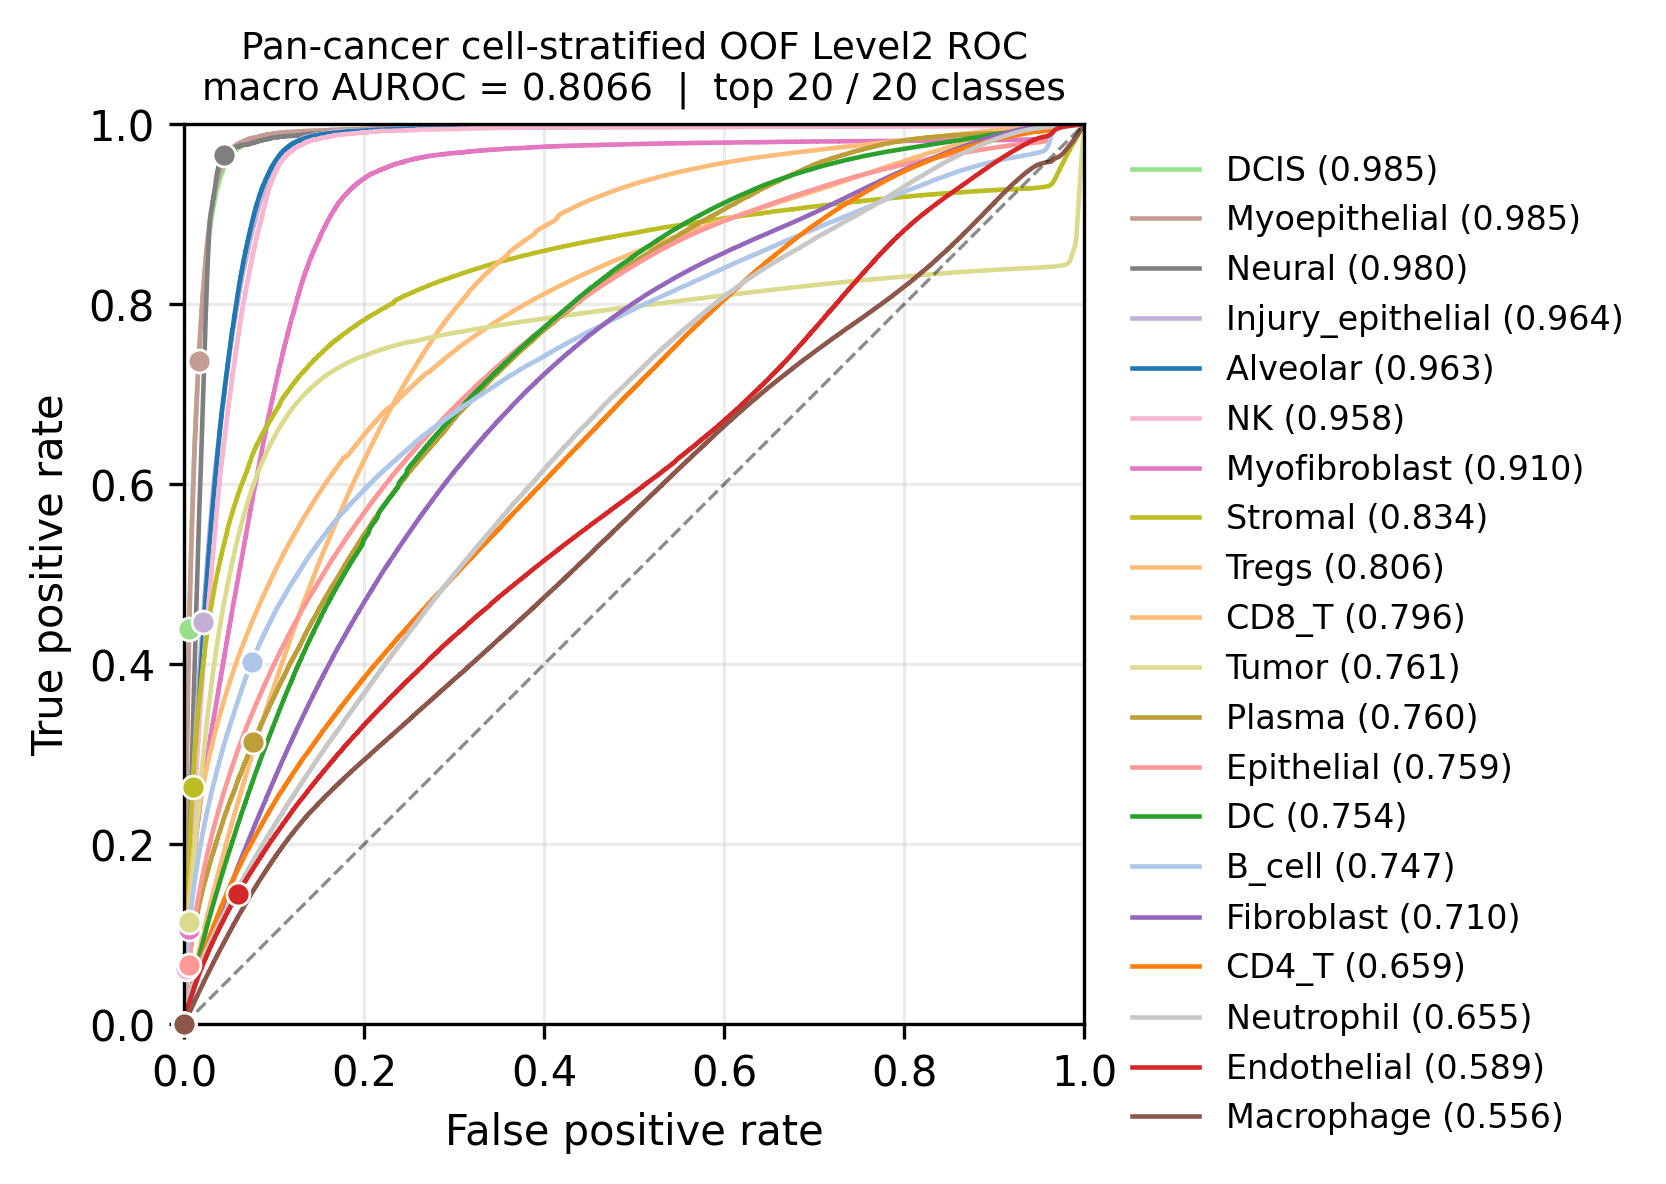

section OOF L2 confusion /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/result_all_spatial/conf_matrix_level2.png


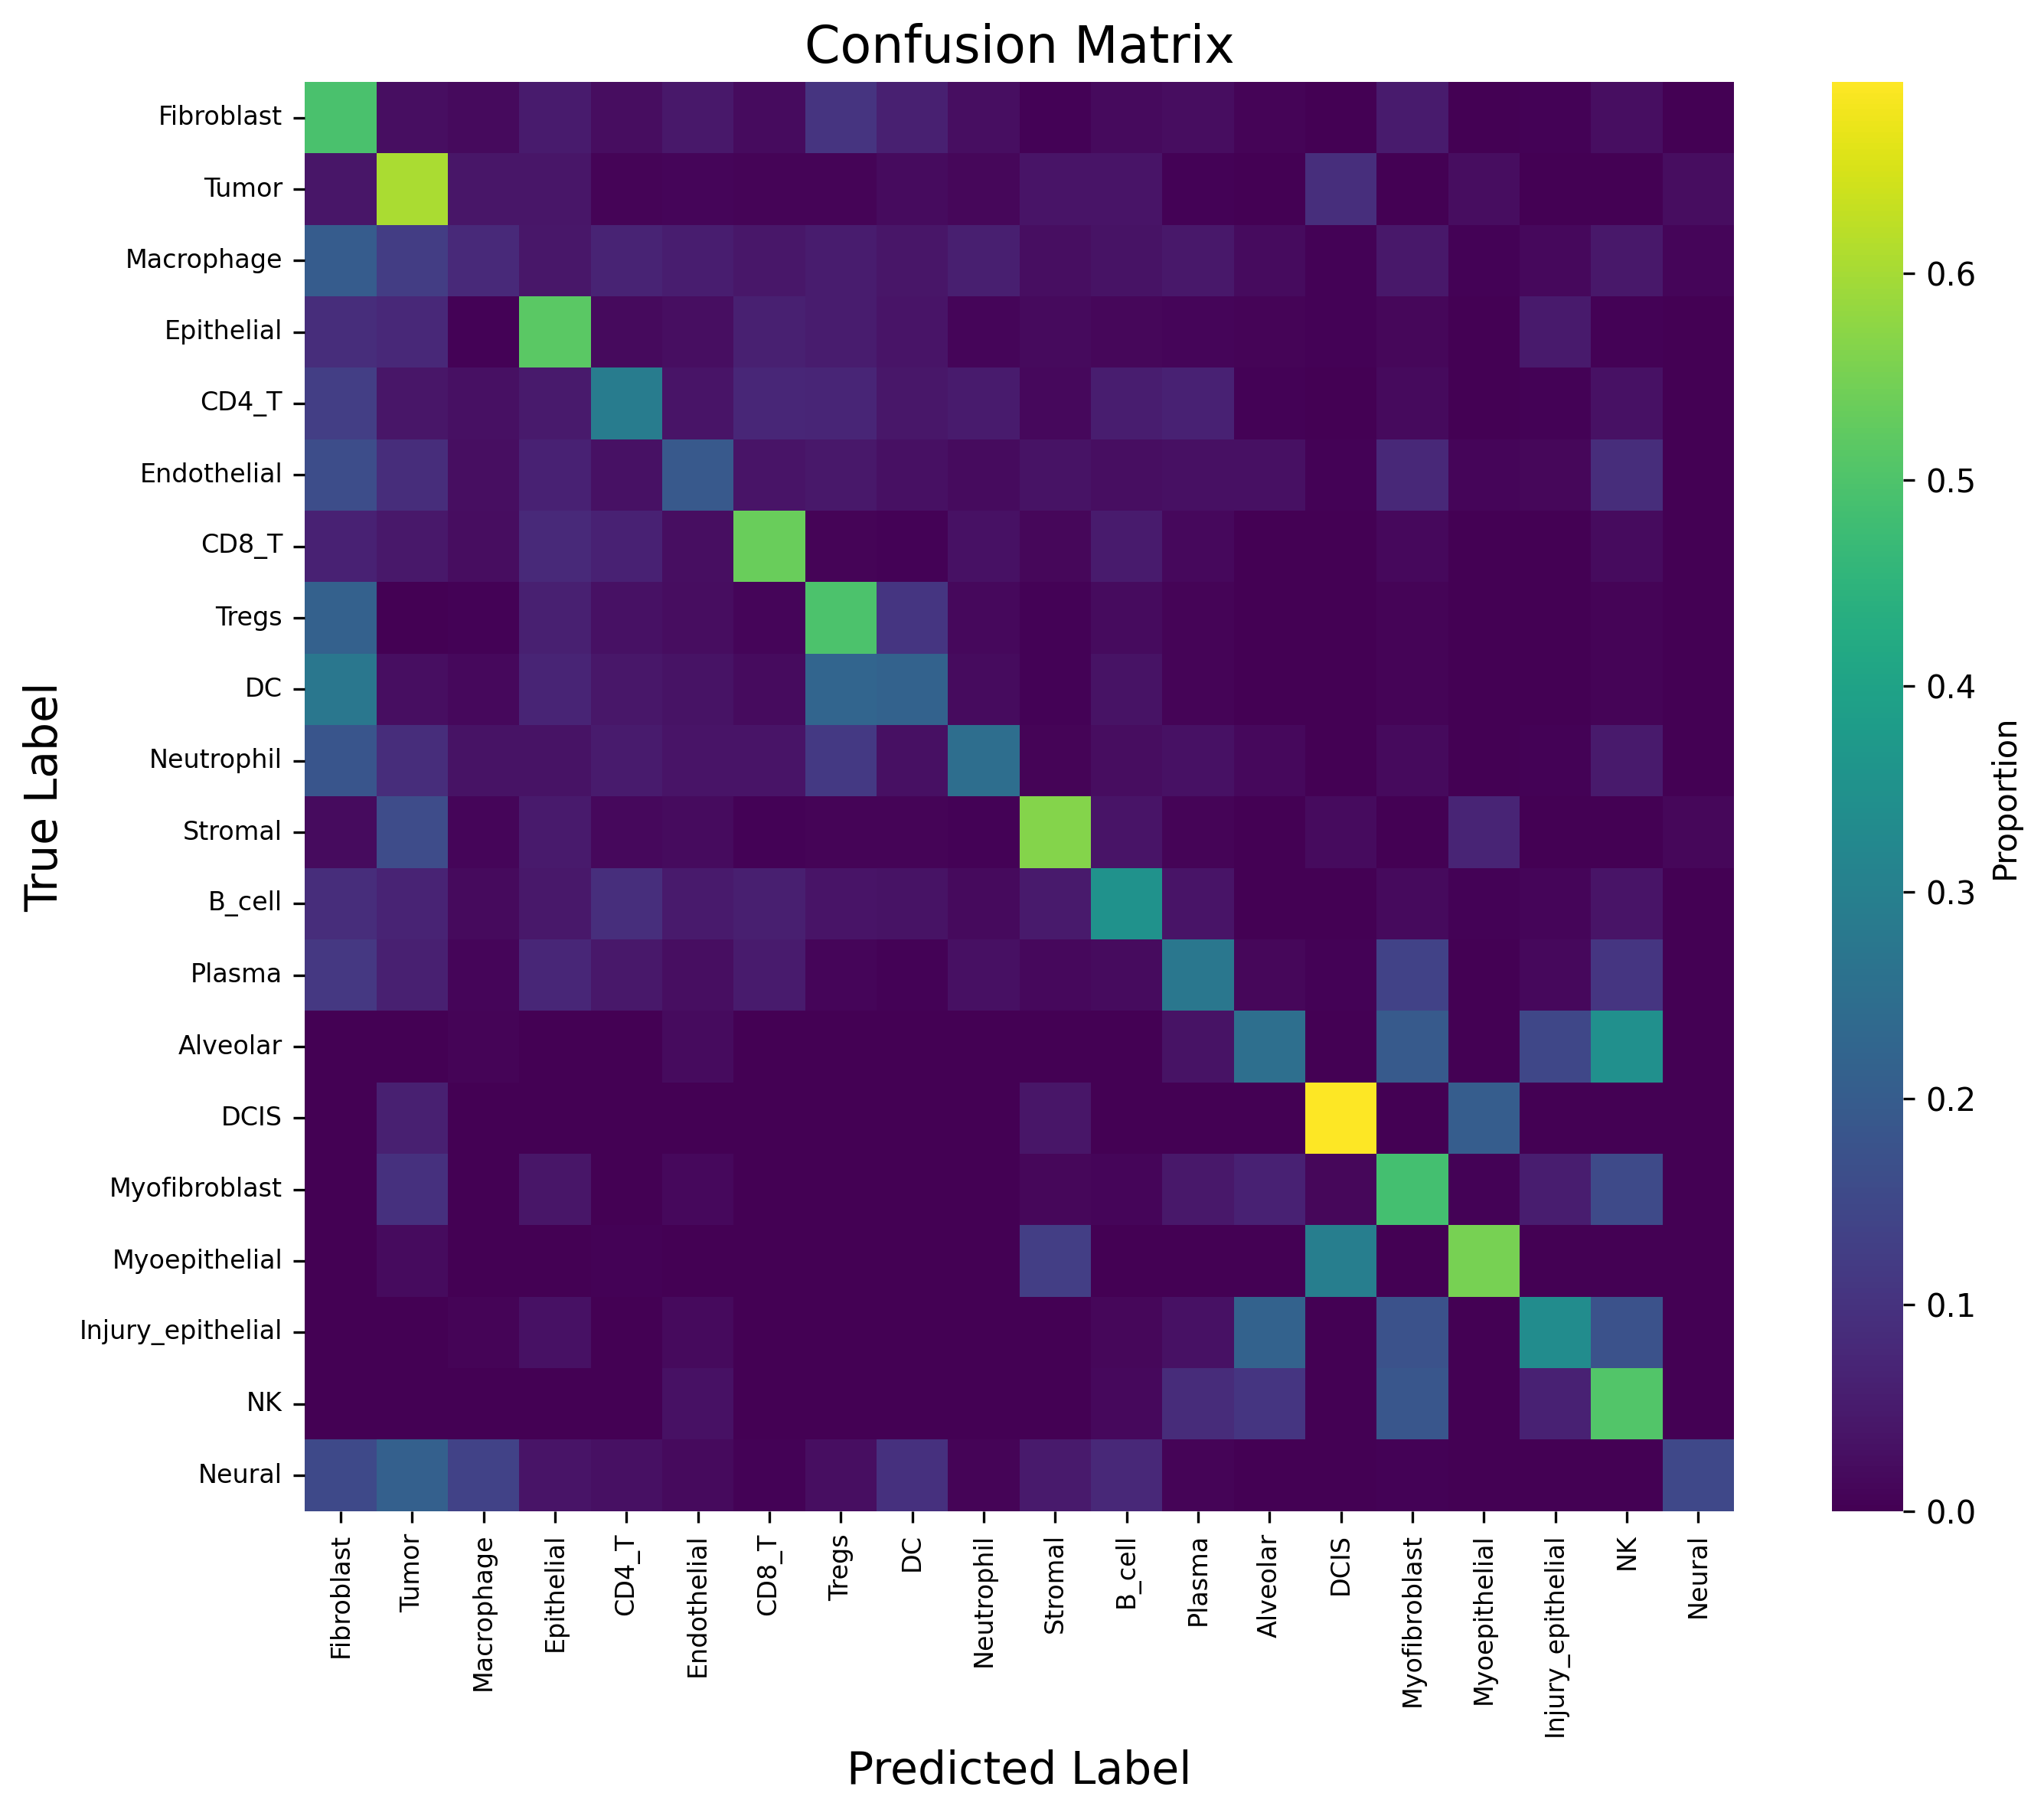

celltype OOF L2 confusion /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/result_cell_stratified_spatial/conf_matrix_level2.png


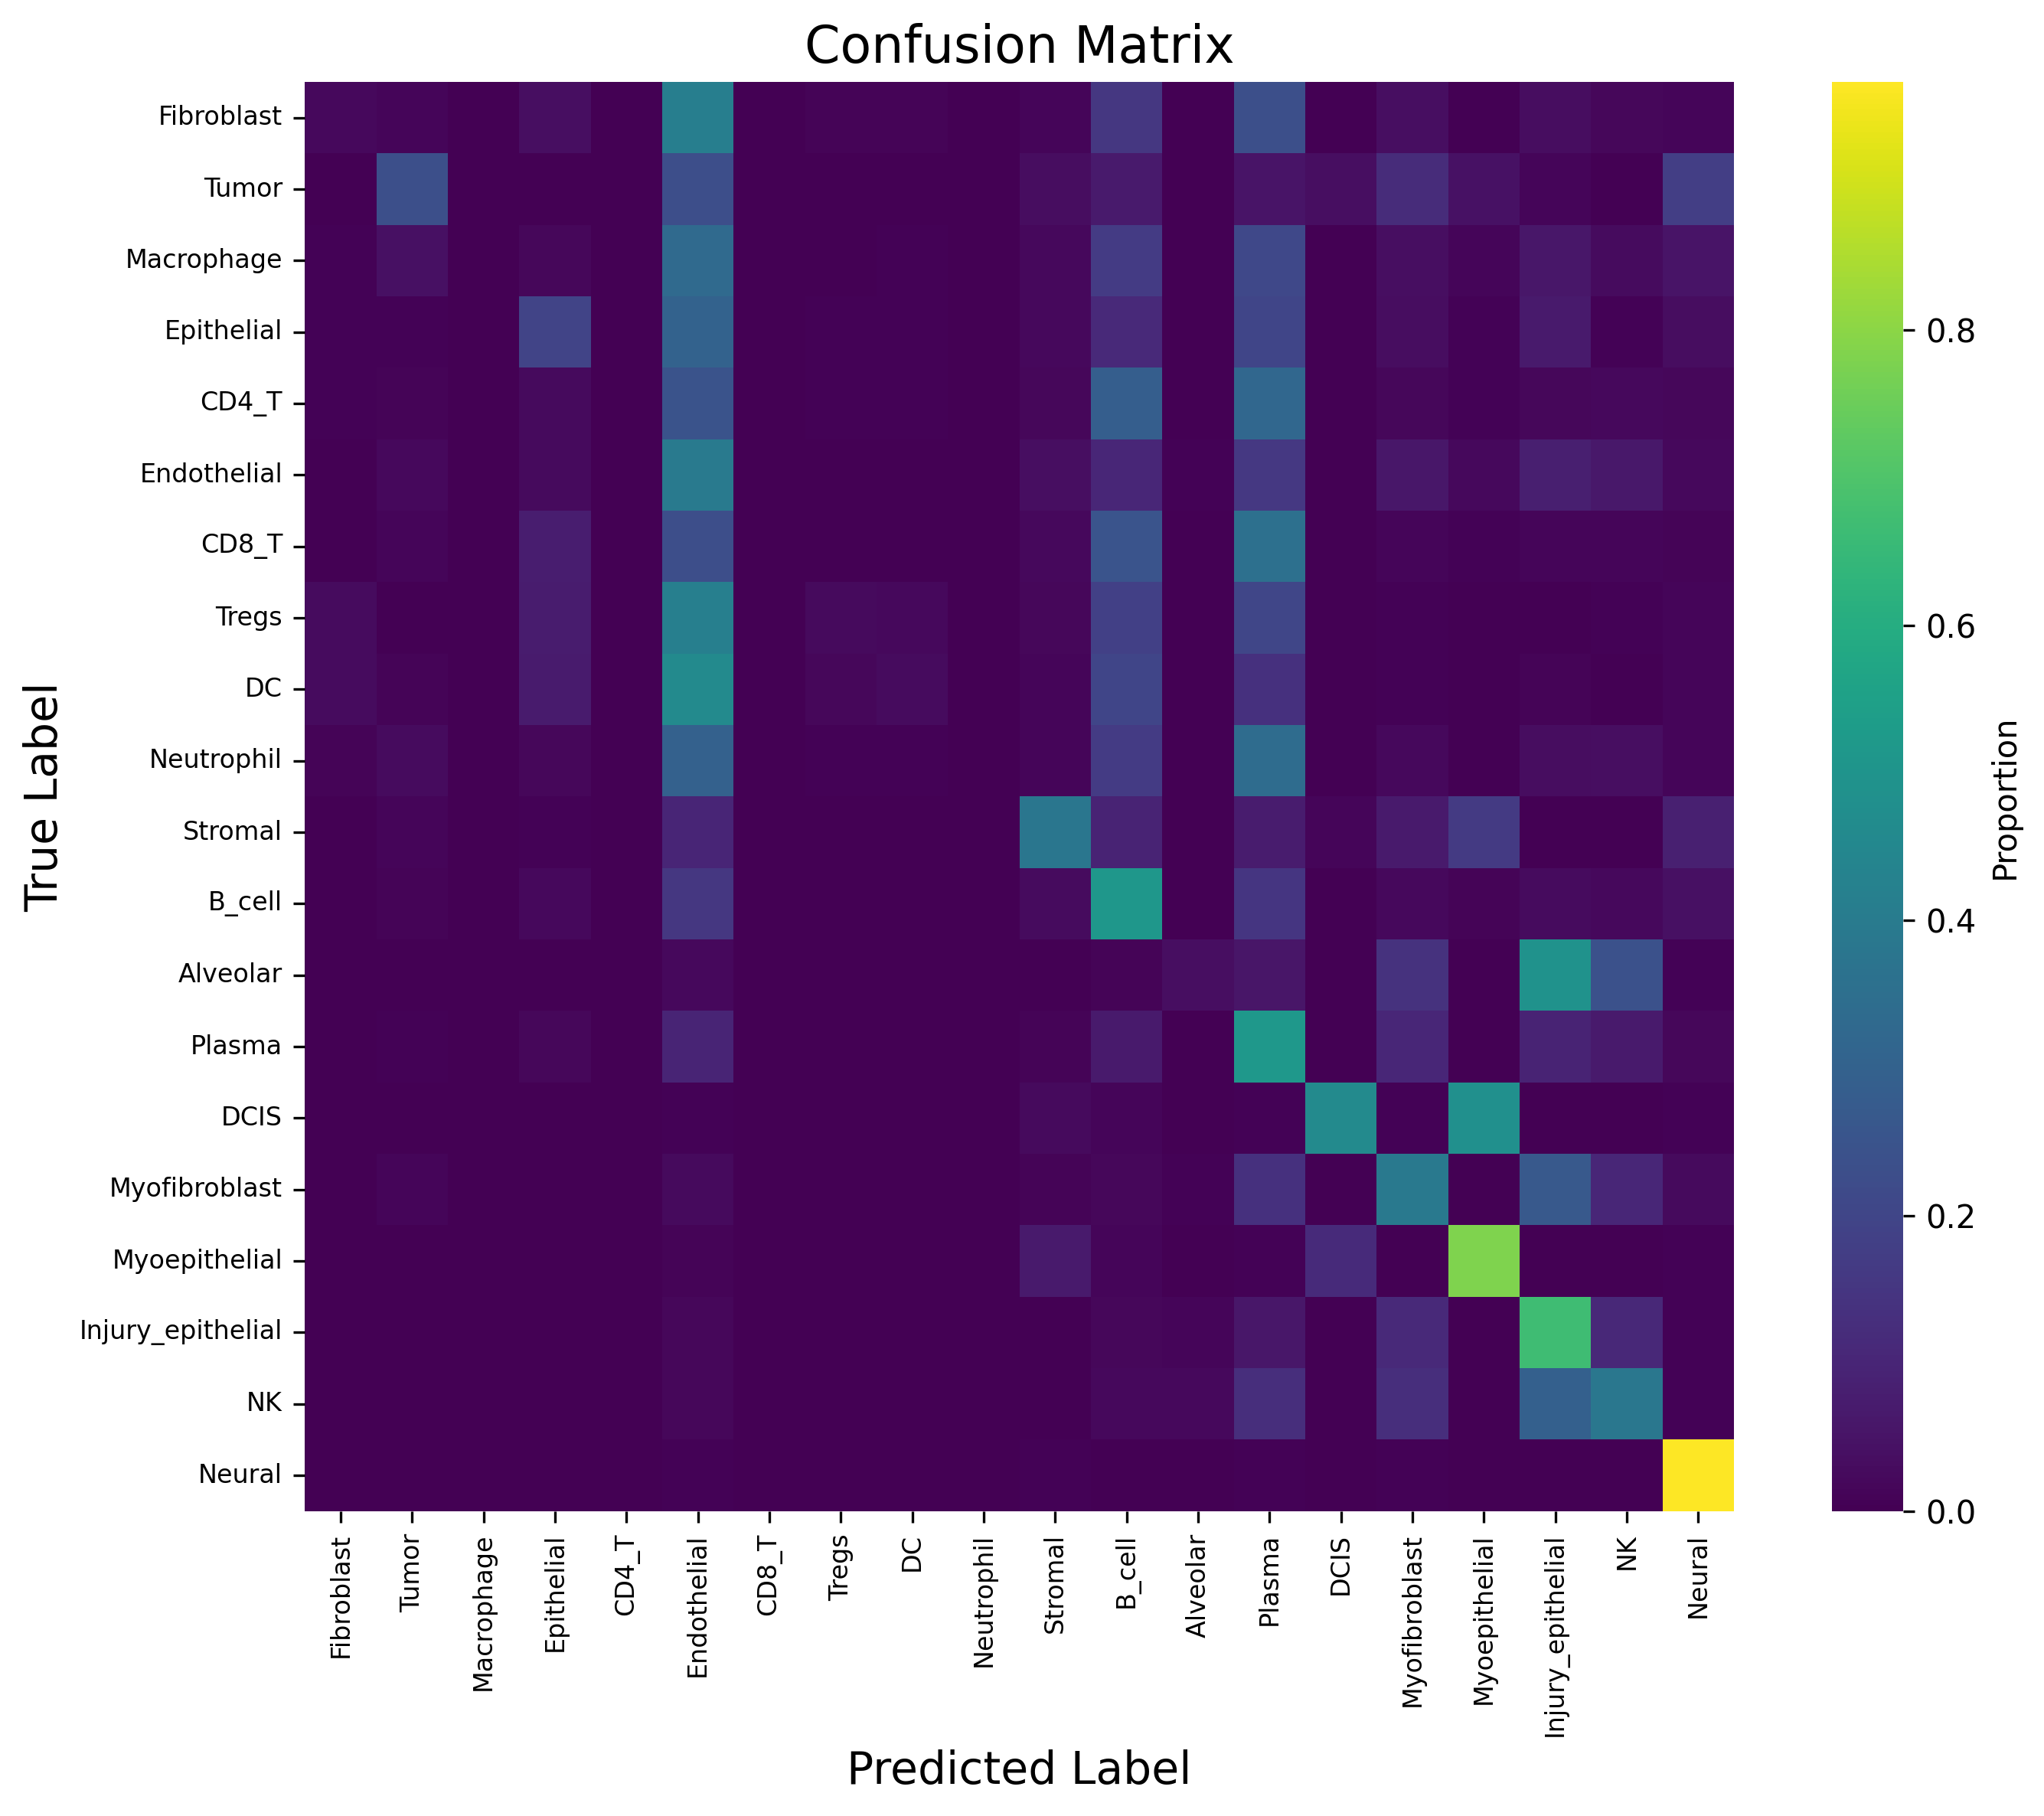

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

PRED_SECTION = REPO / "data" / "PanCancer" / "pred_all_spatial"
PRED_CELL = REPO / "data" / "PanCancer" / "pred_cell_stratified_spatial"
RES_SECTION = REPO / "data" / "PanCancer" / "result_all_spatial"
RES_CELL = REPO / "data" / "PanCancer" / "result_cell_stratified_spatial"
CKPT_SECTION = RES_SECTION / "cross_dataset_cv" / "D_emph_L2_spatial_pancancer"
CKPT_CELL = RES_CELL / "cross_dataset_cv" / "D_emph_L2_spatial_pancancer_cellstrat"
OUT_CMP = PRED_CELL / "pooled_roc"
OUT_CMP.mkdir(parents=True, exist_ok=True)


def _n_sample_dirs(root: Path) -> int:
    roc = root / "stardist_roc"
    return len([p for p in roc.iterdir() if p.is_dir()]) if roc.is_dir() else 0


inv = pd.DataFrame(
    [
        {
            "protocol": "cross-section",
            "best_mlp": (CKPT_SECTION / "best_mlp_gpu.pt").is_file(),
            "n_fold_ckpt": len(list(CKPT_SECTION.glob("hce_group_fold_*.pt"))),
            "pred_roc_dirs": _n_sample_dirs(PRED_SECTION),
        },
        {
            "protocol": "cross-celltype",
            "best_mlp": (CKPT_CELL / "best_mlp_gpu.pt").is_file(),
            "n_fold_ckpt": len(list(CKPT_CELL.glob("hce_group_fold_*.pt"))),
            "pred_roc_dirs": _n_sample_dirs(PRED_CELL),
        },
    ]
)
display(inv)

oof_rows = []
for name, path in (
    ("cross-section", RES_SECTION / "validation_internal_metrics.csv"),
    ("cross-celltype", RES_CELL / "validation_internal_metrics.csv"),
):
    if path.is_file():
        row = pd.read_csv(path).iloc[0].to_dict()
        row["protocol"] = name
        oof_rows.append(row)
oof_sum = pd.DataFrame(oof_rows)
if not oof_sum.empty:
    cols = [c for c in ("protocol", "n_cells", "n_folds", "best_fold", "oof_l2_macro_auc", "cv_l2_macro_f1_mean") if c in oof_sum]
    display(oof_sum[cols])
    print(
        "OOF L2 macro AUROC  section={:.4f}  celltype={:.4f}".format(
            float(oof_sum.loc[oof_sum.protocol == "cross-section", "oof_l2_macro_auc"].iloc[0]),
            float(oof_sum.loc[oof_sum.protocol == "cross-celltype", "oof_l2_macro_auc"].iloc[0]),
        )
    )

auc_cols = ["macro_auc_L1_cells", "macro_auc_L12_cells", "macro_auc_L2_cells"]
ds_tabs = []
for name, pred in (("section", PRED_SECTION), ("celltype", PRED_CELL)):
    met = pred / "metrics_per_section.csv"
    if met.is_file():
        df = pd.read_csv(met)
        g = df.groupby("dataset")[auc_cols].mean()
        g.columns = [f"{c.replace('macro_auc_', '').replace('_cells', '')}_{name}" for c in g.columns]
        ds_tabs.append(g)
if ds_tabs:
    ds_cmp = ds_tabs[0].join(ds_tabs[1:], how="outer")
    display(ds_cmp)
    plot_cols = [c for c in ds_cmp.columns if c.startswith("L2_")]
    if plot_cols:
        ax = ds_cmp[plot_cols].plot(kind="bar", figsize=(8.5, 3.6), color=["steelblue", "darkorange"])
        ax.set_ylim(0.4, 1.0)
        ax.set_ylabel("mean per-section L2 AUROC")
        ax.set_title("Predict: per-dataset mean L2 AUROC (section vs celltype)")
        ax.legend(["cross-section", "cross-celltype"])
        plt.tight_layout()
        plt.show()

for title, path in (
    ("section OOF L2 ROC", RES_SECTION / "roc_internal_level2_oof.png"),
    ("celltype OOF L2 ROC", RES_CELL / "roc_internal_level2_oof.png"),
    ("section OOF L2 confusion", RES_SECTION / "conf_matrix_level2.png"),
    ("celltype OOF L2 confusion", RES_CELL / "conf_matrix_level2.png"),
):
    if path.is_file():
        print(title, path)
        display(Image(filename=str(path), width=520))


,fold,section_OOF_L1,section_OOF_L12,section_OOF_L2,section_OOF_sum,section_OOF_L2_f1,section_best_epoch,cell_OOF_L1,cell_OOF_L12,cell_OOF_L2,cell_OOF_sum,cell_OOF_L2_f1,cell_best_epoch
0,0,0.855409,0.856646,0.903856,2.615911,0.293737,4,0.736275,0.747769,0.810227,2.294271,0.124435,0
1,1,0.813139,0.811372,0.870913,2.495423,0.287483,12,0.736433,0.746975,0.808949,2.292357,0.120361,0
2,2,0.834711,0.830789,0.871047,2.536548,0.251782,8,0.735600,0.747756,0.808626,2.291982,0.116331,0
3,3,0.815737,0.834062,0.883107,2.532905,0.294302,24,0.727978,0.739251,0.800184,2.267413,0.117410,0
4,4,0.806103,0.819338,0.877650,2.503091,0.333193,11,0.735037,0.744103,0.805458,2.284598,0.121694,31


Fold OOF (full val after each fold). celltype best_epoch=0 on folds 0-3 is the resume placeholder; those folds still have OOF metrics.


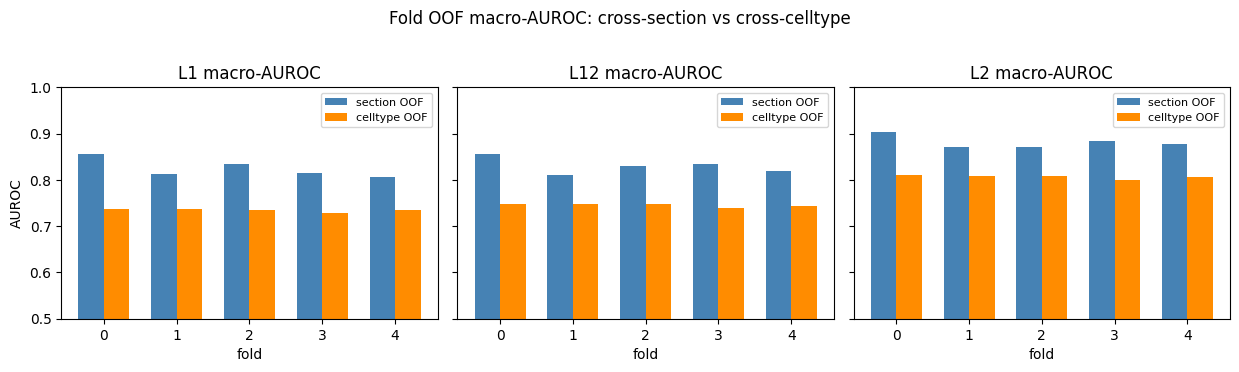

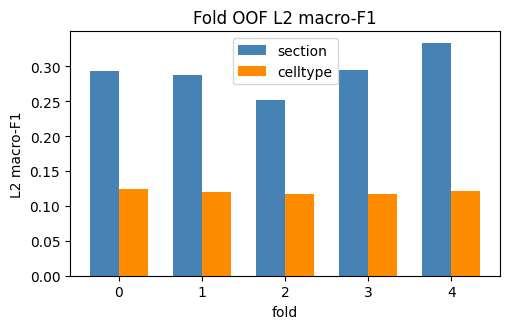

In [4]:
def _load_fold_oof(path: Path, prefix: str) -> pd.DataFrame:
    df = pd.read_csv(path)
    keep = {
        "fold": "fold",
        "l1_head_macro_auc": f"{prefix}_OOF_L1",
        "l12_macro_auc": f"{prefix}_OOF_L12",
        "l2_macro_auc": f"{prefix}_OOF_L2",
        "three_tier_auc_sum": f"{prefix}_OOF_sum",
        "l2_macro_f1": f"{prefix}_OOF_L2_f1",
        "best_epoch": f"{prefix}_best_epoch",
    }
    out = df.loc[:, [c for c in keep if c in df.columns]].rename(columns=keep)
    return out.set_index("fold")


cmp = pd.DataFrame({"fold": range(5)}).set_index("fold")
sec_csv = CKPT_SECTION / "group_cv_folds.csv"
cell_csv = CKPT_CELL / "group_cv_folds.csv"
if sec_csv.is_file():
    cmp = cmp.join(_load_fold_oof(sec_csv, "section"))
if cell_csv.is_file():
    cmp = cmp.join(_load_fold_oof(cell_csv, "cell"))
cmp = cmp.reset_index()
display(cmp)

print(
    "Fold OOF (full val after each fold). "
    "celltype best_epoch=0 on folds 0-3 is the resume placeholder; those folds still have OOF metrics."
)

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6), sharey=True)
for ax, tier, scol, ccol in (
    (axes[0], "L1", "section_OOF_L1", "cell_OOF_L1"),
    (axes[1], "L12", "section_OOF_L12", "cell_OOF_L12"),
    (axes[2], "L2", "section_OOF_L2", "cell_OOF_L2"),
):
    x = cmp["fold"]
    w = 0.35
    if scol in cmp:
        ax.bar(x - w / 2, cmp[scol], width=w, label="section OOF", color="steelblue")
    if ccol in cmp:
        ax.bar(x + w / 2, cmp[ccol], width=w, label="celltype OOF", color="darkorange")
    ax.set_title(f"{tier} macro-AUROC")
    ax.set_xlabel("fold")
    ax.set_xticks(list(range(5)))
    ax.set_ylim(0.5, 1.0)
    ax.legend(fontsize=8)
axes[0].set_ylabel("AUROC")
fig.suptitle("Fold OOF macro-AUROC: cross-section vs cross-celltype", y=1.02)
fig.tight_layout()
plt.show()

if {"section_OOF_L2_f1", "cell_OOF_L2_f1"} <= set(cmp.columns):
    fig, ax = plt.subplots(figsize=(5.2, 3.4))
    ax.bar(cmp["fold"] - 0.175, cmp["section_OOF_L2_f1"], width=0.35, label="section", color="steelblue")
    ax.bar(cmp["fold"] + 0.175, cmp["cell_OOF_L2_f1"], width=0.35, label="celltype", color="darkorange")
    ax.set_xticks(list(range(5)))
    ax.set_xlabel("fold")
    ax.set_ylabel("L2 macro-F1")
    ax.set_title("Fold OOF L2 macro-F1")
    ax.legend()
    fig.tight_layout()
    plt.show()



=== L2 | discovering validation_external_stardist_matched_AUROC.csv ===
  BRCA__rep1: 157,016 cells, 20 local classes
  BRCA__rep2: 107,180 cells, 20 local classes
  CRC__P1CRC: 149,492 cells, 20 local classes
  CRC__P2CRC: 202,900 cells, 20 local classes
  CRC__P5CRC: 116,121 cells, 20 local classes
  GBM__P174511_Initial: 35,961 cells, 20 local classes
  GBM__P179161_Recurrent: 135,055 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg002: 3,098 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg004: 12,062 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg005: 4,090 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg006: 5,225 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg007: 10,544 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg008: 6,964 cells, 20 local classe

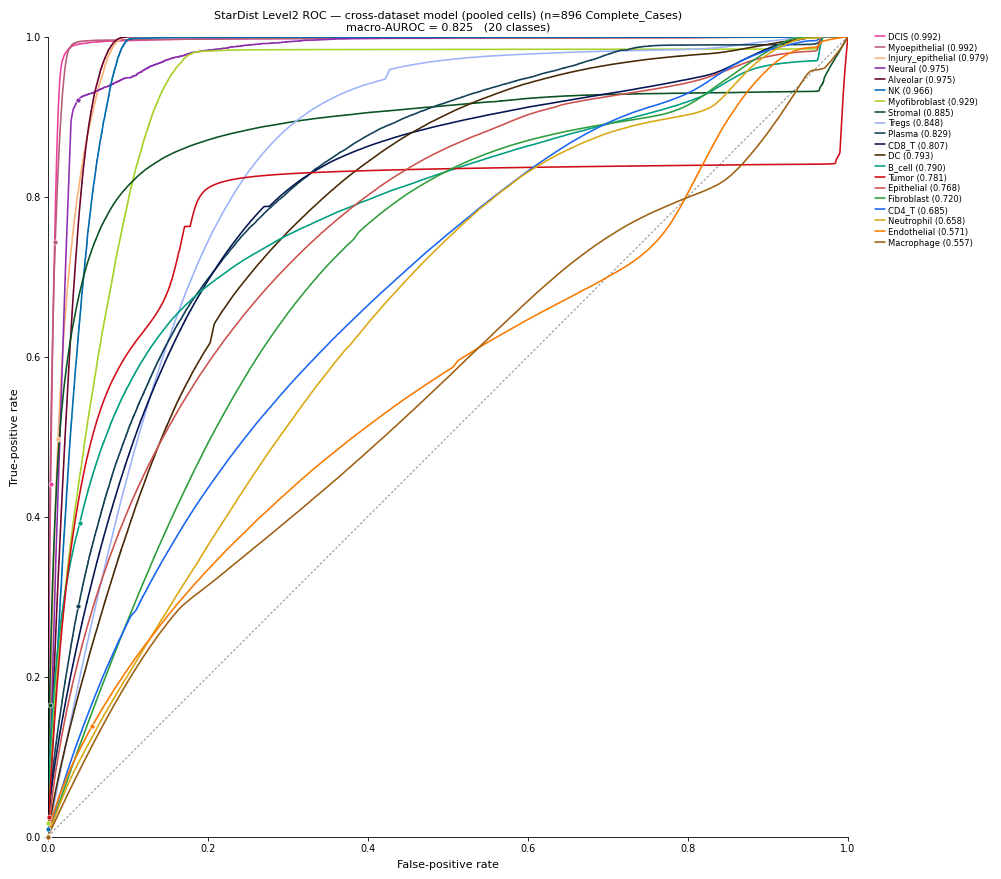

Pooled macro AUROC (L2): 0.8249
  ✓ Saved AUROC bars: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_cell_stratified_spatial/pooled_roc/roc_stardist_l2_cross_dataset_all_Complete_Cases_per_class_auc.pdf


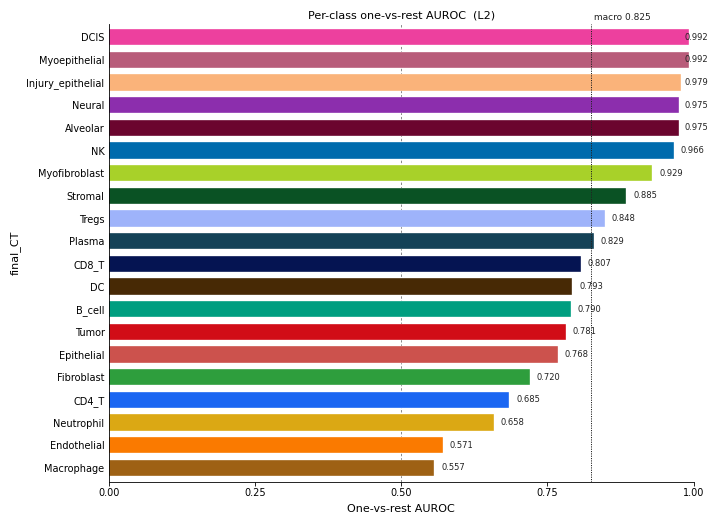


=== L12 | discovering validation_external_stardist_matched_AUROC_level12.csv ===
  BRCA__rep1: 157,016 cells, 8 local classes
  BRCA__rep2: 107,180 cells, 8 local classes
  CRC__P1CRC: 149,492 cells, 8 local classes
  CRC__P2CRC: 202,900 cells, 8 local classes
  CRC__P5CRC: 116,121 cells, 8 local classes
  GBM__P174511_Initial: 35,961 cells, 8 local classes
  GBM__P179161_Recurrent: 135,055 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg002: 3,098 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg004: 12,062 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg005: 4,090 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg006: 5,225 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg007: 10,544 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg008: 6,964 cells, 8 local classes
  GI

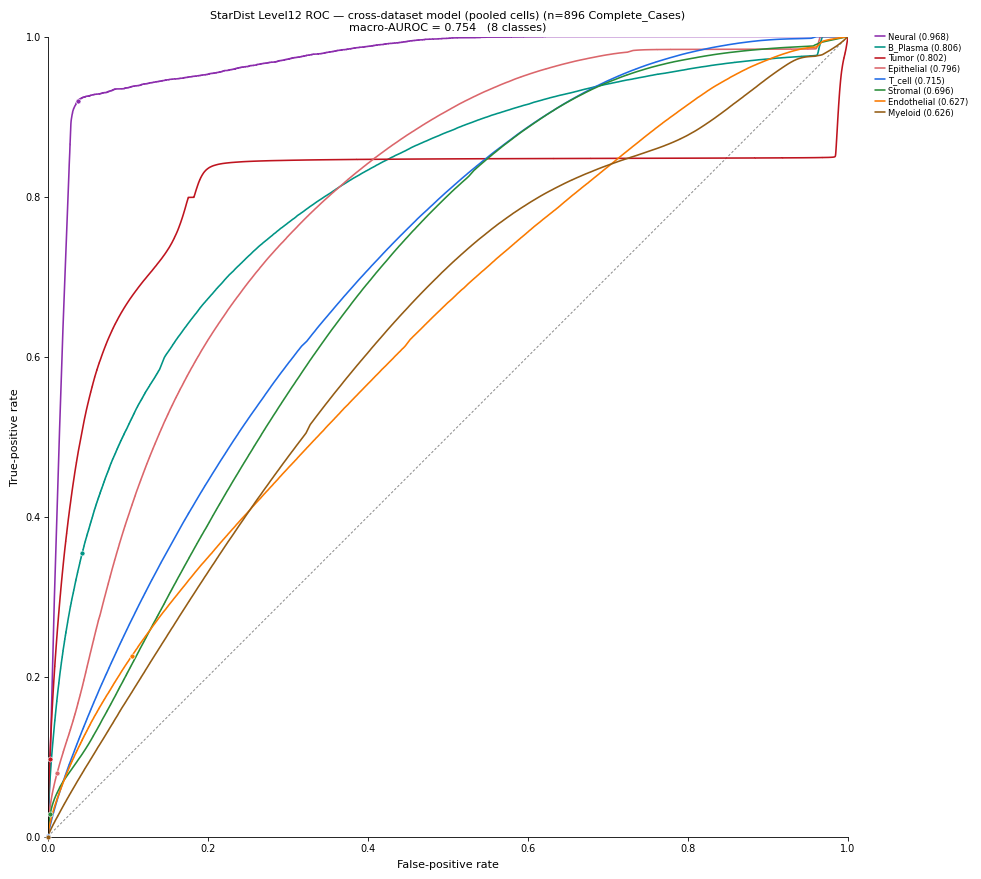

Pooled macro AUROC (L12): 0.7544
  ✓ Saved AUROC bars: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_cell_stratified_spatial/pooled_roc/roc_stardist_l12_cross_dataset_all_Complete_Cases_per_class_auc.pdf


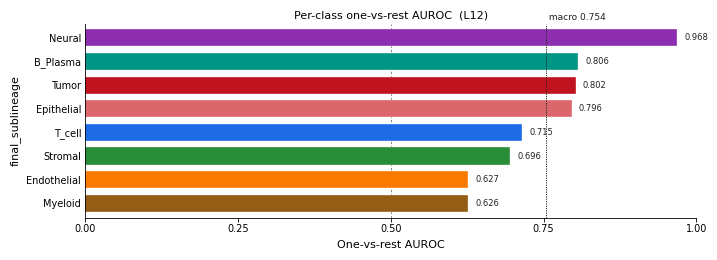


=== L1 | discovering validation_external_stardist_matched_AUROC_level1.csv ===
  BRCA__rep1: 157,016 cells, 5 local classes
  BRCA__rep2: 107,180 cells, 5 local classes
  CRC__P1CRC: 149,492 cells, 5 local classes
  CRC__P2CRC: 202,900 cells, 5 local classes
  CRC__P5CRC: 116,121 cells, 5 local classes
  GBM__P174511_Initial: 35,961 cells, 5 local classes
  GBM__P179161_Recurrent: 135,055 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg002: 3,098 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg004: 12,062 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg005: 4,090 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg006: 5,225 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg007: 10,544 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg008: 6,964 cells, 5 local classes
  GIST

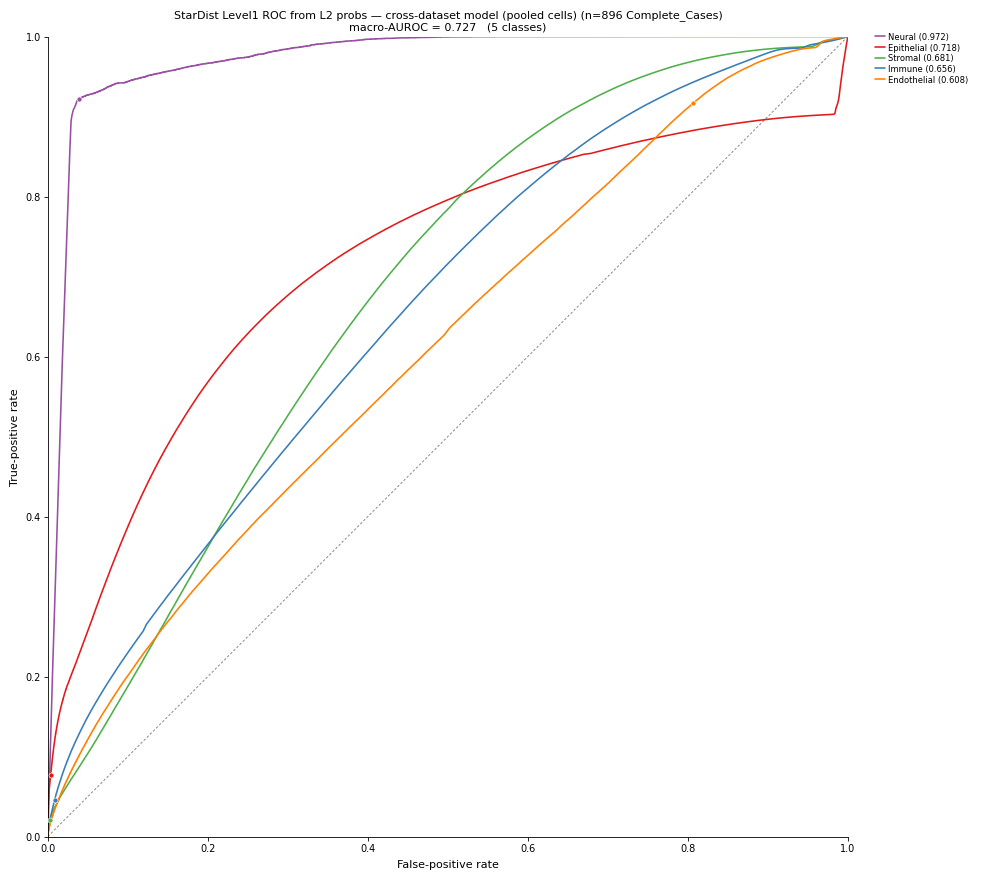

Pooled macro AUROC (L1): 0.7270
  ✓ Saved AUROC bars: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_cell_stratified_spatial/pooled_roc/roc_stardist_l1_cross_dataset_all_Complete_Cases_per_class_auc.pdf


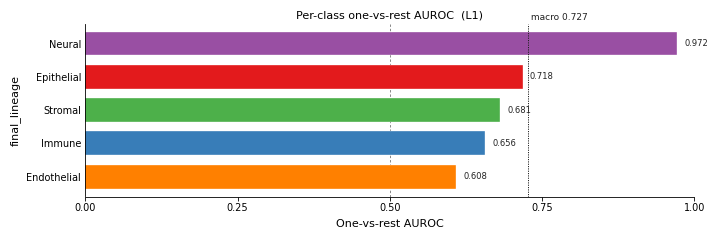

=== pooled macro AUROC (same estimator as the section plots above) ===
cross-section    L2   0.8946823988003292
cross-section    L12  0.8477393495235448
cross-section    L1   0.8401971701557475
cross-celltype   L2   0.824912549830039
cross-celltype   L12  0.754436743082145
cross-celltype   L1   0.7269572194558528


In [5]:
ROC_ROOT_CELL = PRED_CELL / "stardist_roc"
if not ROC_ROOT_CELL.is_dir() or not any(ROC_ROOT_CELL.iterdir()):
    raise FileNotFoundError(
        f"No per-section AUROC CSVs under {ROC_ROOT_CELL}. "
        "Run: bash code/PanCancer/demo.sh celltype predict"
    )

results_cell = plot_pooled_stardist_tier_rocs(
    ROC_ROOT_CELL,
    OUT_CMP,
    tiers=("l2", "l12", "l1"),
    layout="pooled_stardist",
    pan_organ="pancancer",
    figsize=(8.0, 8.0),
    show_barplot=True,
    save_per_class_csv=True,
    show=True,
)

print("=== pooled macro AUROC (same estimator as the section plots above) ===")
_section_results = results if "results" in dir() else {}
for proto, recs, src in (
    ("cross-section", _section_results, PRED_SECTION / "pooled_roc"),
    ("cross-celltype", results_cell, OUT_CMP),
):
    for tier in ("l2", "l12", "l1"):
        rec = (recs or {}).get(tier) or {}
        info = rec.get("roc_info") or {}
        auc = info.get("macro_auc")
        if auc is None:
            csv = src / f"roc_stardist_{tier}_cross_dataset_all_Complete_Cases_per_class_auc.csv"
            if csv.is_file():
                auc = float(pd.read_csv(csv)["auc_ovr"].mean())
        print(f"{proto:16s} {tier.upper():3s}  {auc}")



=== L2 per-class pooled OvR AUROC ===


,class_name,auc_section,n_pos_section,auc_cell,n_pos_cell,delta_cell_minus_section
3,Myoepithelial,0.979241,18010,0.991589,18010,0.012348
0,DCIS,0.987662,41775,0.992051,41775,0.004388
2,Injury_epithelial,0.979751,14090,0.979095,14090,-0.000656
4,Alveolar,0.978058,58050,0.974623,58050,-0.003434
5,NK,0.971632,11655,0.965771,11655,-0.005861
1,Neural,0.982206,10848,0.974896,10848,-0.007310
7,Myofibroblast,0.952294,38977,0.929458,38977,-0.022836
14,DC,0.839909,316538,0.792512,316538,-0.047397
12,Plasma,0.878341,61271,0.829482,61271,-0.048859
10,Tregs,0.901332,322139,0.847750,322139,-0.053583


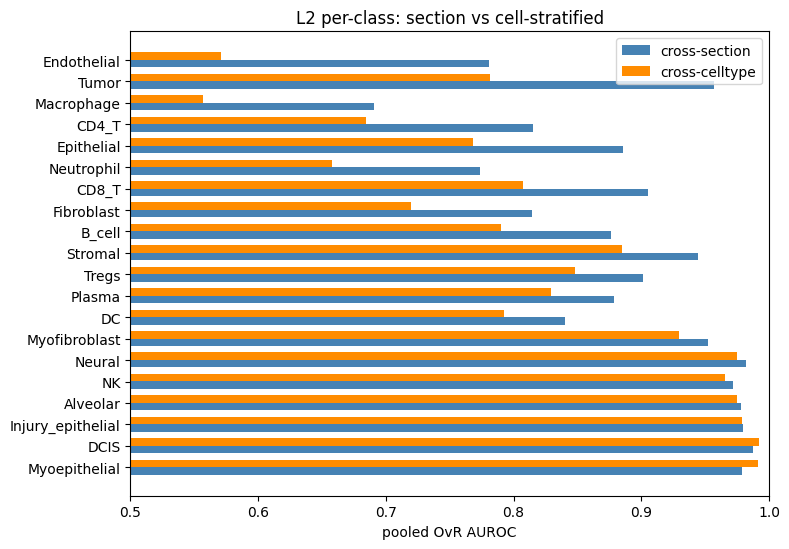


=== L12 per-class pooled OvR AUROC ===


,class_name,auc_section,n_pos_section,auc_cell,n_pos_cell,delta_cell_minus_section
0,Neural,0.977111,10848,0.967865,10848,-0.009246
3,B_Plasma,0.851757,197065,0.806229,197065,-0.045528
7,Myeloid,0.710408,1180381,0.626046,1180381,-0.084362
2,Epithelial,0.880752,647123,0.795814,647123,-0.084938
5,Stromal,0.800253,1048592,0.695567,1048592,-0.104686
4,T_cell,0.820984,1215636,0.714857,1215636,-0.106128
6,Endothelial,0.780338,445047,0.626874,445047,-0.153464
1,Tumor,0.960311,882379,0.802242,882379,-0.158069


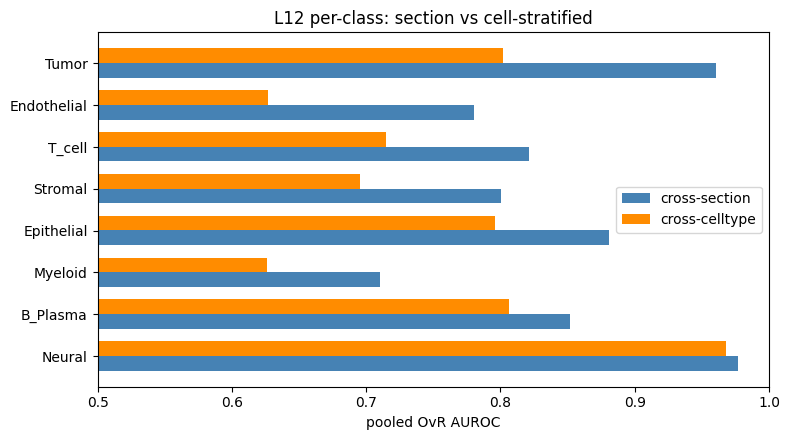


=== L1 per-class pooled OvR AUROC ===


,class_name,auc_section,n_pos_section,auc_cell,n_pos_cell,delta_cell_minus_section
0,Neural,0.979875,10848,0.971834,10848,-0.008041
2,Stromal,0.787782,1048592,0.680764,1048592,-0.107018
3,Immune,0.782229,2593082,0.655808,2593082,-0.126421
1,Epithelial,0.872983,1529502,0.718073,1529502,-0.154911
4,Endothelial,0.778117,445047,0.608308,445047,-0.169810


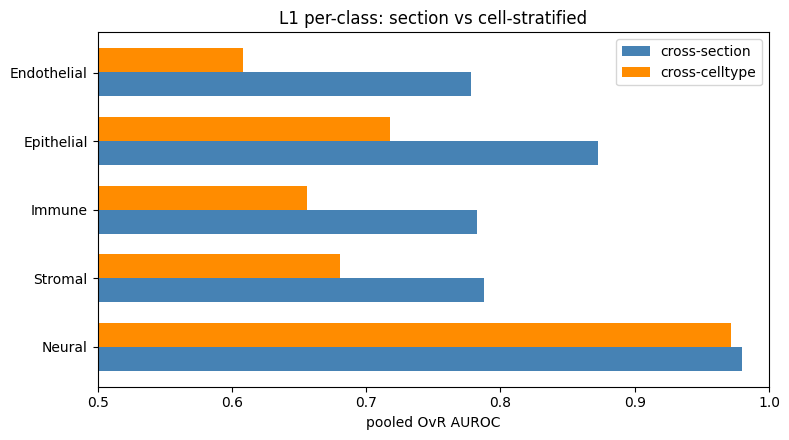

In [6]:
def _load_per_class(root: Path, tier: str):
    path = root / f"roc_stardist_{tier}_cross_dataset_all_Complete_Cases_per_class_auc.csv"
    if not path.is_file():
        return None
    df = pd.read_csv(path)
    return df.rename(columns={"auc_ovr": "auc"})[["class_name", "auc", "n_pos"]]


sec_pool = PRED_SECTION / "pooled_roc"
cell_pool = OUT_CMP
any_cmp = False
for tier in ("l2", "l12", "l1"):
    a = _load_per_class(sec_pool, tier)
    b = _load_per_class(cell_pool, tier)
    if a is None or b is None:
        print(f"{tier.upper()}: need both per-class CSVs (section exists={a is not None}, cell={b is not None})")
        continue
    any_cmp = True
    m = a.merge(b, on="class_name", suffixes=("_section", "_cell"))
    m["delta_cell_minus_section"] = m["auc_cell"] - m["auc_section"]
    m = m.sort_values("delta_cell_minus_section", ascending=False)
    print(f"\n=== {tier.upper()} per-class pooled OvR AUROC ===")
    display(m)
    fig, ax = plt.subplots(figsize=(8.0, max(4.5, 0.28 * len(m))))
    y = range(len(m))
    ax.barh(list(y), m["auc_section"], height=0.35, label="cross-section", color="steelblue")
    ax.barh([i + 0.35 for i in y], m["auc_cell"], height=0.35, label="cross-celltype", color="darkorange")
    ax.set_yticks([i + 0.17 for i in y], m["class_name"])
    ax.set_xlim(0.5, 1.0)
    ax.set_xlabel("pooled OvR AUROC")
    ax.set_title(f"{tier.upper()} per-class: section vs cell-stratified")
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUT_CMP / f"compare_{tier}_per_class_auc_section_vs_cellstrat.png", dpi=150)
    plt.show()

if not any_cmp:
    print("Run the previous cell first so celltype pooled per-class CSVs exist.")
